In [2]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import torch

# Connect Google Drive
drive.mount("/content/drive")

# Project directories
BASE = Path("/content/drive/MyDrive/TrustFact")
DATA_DIR = BASE / "data/raw/liar"
OUTPUT_DIR = BASE / "results/week4/distilbert"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# LIAR dataset column names
columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

# Load training dataset
train_df = pd.read_csv(
    DATA_DIR / "train.tsv",
    sep="\t",
    header=None,
    names=columns
)

# Load validation dataset
valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

print("Training samples:", len(train_df))
print("Validation samples:", len(valid_df))

Mounted at /content/drive
Training samples: 10240
Validation samples: 1284


In [3]:
labels = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

label2id = {
    label: i for i, label in enumerate(labels)
}

id2label = {
    i: label for label, i in label2id.items()
}

train_df["label_id"] = train_df["label"].map(label2id)
valid_df["label_id"] = valid_df["label"].map(label2id)

assert train_df["label_id"].notna().all()
assert valid_df["label_id"].notna().all()

train_df["label_id"] = train_df["label_id"].astype(int)
valid_df["label_id"] = valid_df["label_id"].astype(int)

print("Label mapping successful!")
print(label2id)

Label mapping successful!
{'pants-fire': 0, 'false': 1, 'barely-true': 2, 'half-true': 3, 'mostly-true': 4, 'true': 5}


In [4]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(6),
    y=train_df["label_id"].to_numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("Class weights:")

for i, weight in enumerate(class_weights):
    print(id2label[i], round(weight.item(), 4))

Class weights:
pants-fire 2.0342
false 0.8555
barely-true 1.0318
half-true 0.8073
mostly-true 0.8699
true 1.0183


In [5]:
from datasets import Dataset
from transformers import AutoTokenizer
from sklearn.metrics import accuracy_score, f1_score

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def prepare_dataset(df):
    data = df[["statement", "label_id"]].copy()
    data["statement"] = data["statement"].fillna("")
    data = data.rename(columns={"label_id": "labels"})

    dataset = Dataset.from_pandas(
        data,
        preserve_index=False
    )

    dataset = dataset.map(
        lambda batch: tokenizer(
            batch["statement"],
            truncation=True,
            max_length=128
        ),
        batched=True
    )

    return dataset.remove_columns(["statement"])

train_dataset = prepare_dataset(train_df)
valid_dataset = prepare_dataset(valid_df)

def compute_metrics(eval_pred):
    logits, true_labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(
            true_labels, predictions
        ),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(valid_dataset))
print("All training variables ready!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/10240 [00:00<?, ? examples/s]

Map:   0%|          | 0/1284 [00:00<?, ? examples/s]

Training dataset: 10240
Validation dataset: 1284
All training variables ready!


In [6]:
required_variables = [
    "train_df",
    "valid_df",
    "train_dataset",
    "valid_dataset",
    "tokenizer",
    "class_weights",
    "compute_metrics",
    "MODEL_NAME",
    "OUTPUT_DIR"
]

for name in required_variables:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )

print("\nGPU available:", torch.cuda.is_available())

train_df READY
valid_df READY
train_dataset READY
valid_dataset READY
tokenizer READY
class_weights READY
compute_metrics READY
MODEL_NAME READY
OUTPUT_DIR READY

GPU available: True


In [7]:
required_variables = [
    "train_df",
    "valid_df",
    "train_dataset",
    "valid_dataset",
    "tokenizer",
    "class_weights",
    "compute_metrics",
    "MODEL_NAME",
    "OUTPUT_DIR"
]

for name in required_variables:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )

print("\nGPU available:", torch.cuda.is_available())

train_df READY
valid_df READY
train_dataset READY
valid_dataset READY
tokenizer READY
class_weights READY
compute_metrics READY
MODEL_NAME READY
OUTPUT_DIR READY

GPU available: True


In [8]:
from transformers import TrainingArguments, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [9]:
from transformers import Trainer
import torch.nn.functional as F

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels_batch = inputs["labels"]
        outputs = model(**inputs)

        loss = F.cross_entropy(
            outputs.logits,
            labels_batch,
            weight=class_weights.to(outputs.logits.device)
        )

        return (loss, outputs) if return_outputs else loss

print("WeightedTrainer ready!")

WeightedTrainer ready!


In [10]:
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments
)

import torch

assert torch.cuda.is_available(), "GPU not available!"

# Set reproducibility seed before model initialization
from transformers import set_seed
set_seed(42)

# Initialize a fresh pretrained model
weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

weighted_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "weighted_checkpoints"),
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy="epoch",
    report_to="none",
    fp16=True,
    seed=42,
    data_seed=42
)

weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Starting weighted DistilBERT training...")

weighted_trainer.train()

weighted_metrics = weighted_trainer.evaluate()

print("\nWEIGHTED DISTILBERT RESULTS")
print("Accuracy:", round(weighted_metrics["eval_accuracy"], 4))
print("Macro-F1:", round(weighted_metrics["eval_macro_f1"], 4))
print("Validation loss:", round(weighted_metrics["eval_loss"], 4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting weighted DistilBERT training...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.748666,1.704101,0.264798,0.257523
2,1.626394,1.673161,0.263240,0.262279
3,1.492594,1.705965,0.267134,0.271723


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
1.492594,1.705965,3,0.267134,0.271723



WEIGHTED DISTILBERT RESULTS
Accuracy: 0.2671
Macro-F1: 0.2717
Validation loss: 1.706


In [11]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Standard DistilBERT",
        "Accuracy": 0.260125,
        "Macro-F1": 0.253645
    },
    {
        "Model": "Weighted DistilBERT",
        "Accuracy": weighted_metrics["eval_accuracy"],
        "Macro-F1": weighted_metrics["eval_macro_f1"]
    },
    {
        "Model": "Optimized Logistic Regression",
        "Accuracy": 0.267134,
        "Macro-F1": 0.261930
    }
])

comparison = comparison.sort_values(
    "Macro-F1", ascending=False
)

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "weighted_distilbert_comparison.csv",
    index=False
)

,Model,Accuracy,Macro-F1
1,Weighted DistilBERT,0.267134,0.271723
2,Optimized Logistic Regression,0.267134,0.261930
0,Standard DistilBERT,0.260125,0.253645


In [12]:
MODEL_SAVE_DIR = OUTPUT_DIR / "weighted_best_model"

weighted_trainer.save_model(str(MODEL_SAVE_DIR))
tokenizer.save_pretrained(str(MODEL_SAVE_DIR))

print("Weighted DistilBERT saved successfully!")
print("Location:", MODEL_SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Weighted DistilBERT saved successfully!
Location: /content/drive/MyDrive/TrustFact/results/week4/distilbert/weighted_best_model


In [13]:
import pandas as pd

print("Weighted DistilBERT evaluation:")
print("Accuracy:", round(weighted_metrics["eval_accuracy"], 4))
print("Macro-F1:", round(weighted_metrics["eval_macro_f1"], 4))
print("Validation loss:", round(weighted_metrics["eval_loss"], 4))

comparison = pd.DataFrame([
    {
        "Model": "Standard DistilBERT",
        "Accuracy": 0.260125,
        "Macro-F1": 0.253645
    },
    {
        "Model": "Weighted DistilBERT",
        "Accuracy": weighted_metrics["eval_accuracy"],
        "Macro-F1": weighted_metrics["eval_macro_f1"]
    },
    {
        "Model": "Optimized Logistic Regression",
        "Accuracy": 0.267134,
        "Macro-F1": 0.261930
    }
])

comparison = comparison.sort_values(
    "Macro-F1", ascending=False
)

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "weighted_distilbert_comparison.csv",
    index=False
)

print("Comparison saved successfully!")

Weighted DistilBERT evaluation:
Accuracy: 0.2671
Macro-F1: 0.2717
Validation loss: 1.706


,Model,Accuracy,Macro-F1
1,Weighted DistilBERT,0.267134,0.271723
2,Optimized Logistic Regression,0.267134,0.261930
0,Standard DistilBERT,0.260125,0.253645


Comparison saved successfully!


In [14]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

output = weighted_trainer.predict(valid_dataset)
predictions = np.argmax(output.predictions, axis=-1)
actual = valid_df["label_id"].to_numpy()

report = classification_report(
    actual,
    predictions,
    labels=list(range(6)),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

report_df.to_csv(
    OUTPUT_DIR / "weighted_distilbert_classification_report.csv"
)

,precision,recall,f1-score,support
pants-fire,0.301370,0.379310,0.335878,116.000000
false,0.317647,0.205323,0.249423,263.000000
barely-true,0.268595,0.274262,0.271399,237.000000
half-true,0.264706,0.254032,0.259259,248.000000
mostly-true,0.281915,0.211155,0.241458,251.000000
true,0.213333,0.378698,0.272921,169.000000
accuracy,0.267134,0.267134,0.267134,0.267134
macro avg,0.274594,0.283797,0.271723,1284.000000
weighted avg,0.276182,0.267134,0.264725,1284.000000


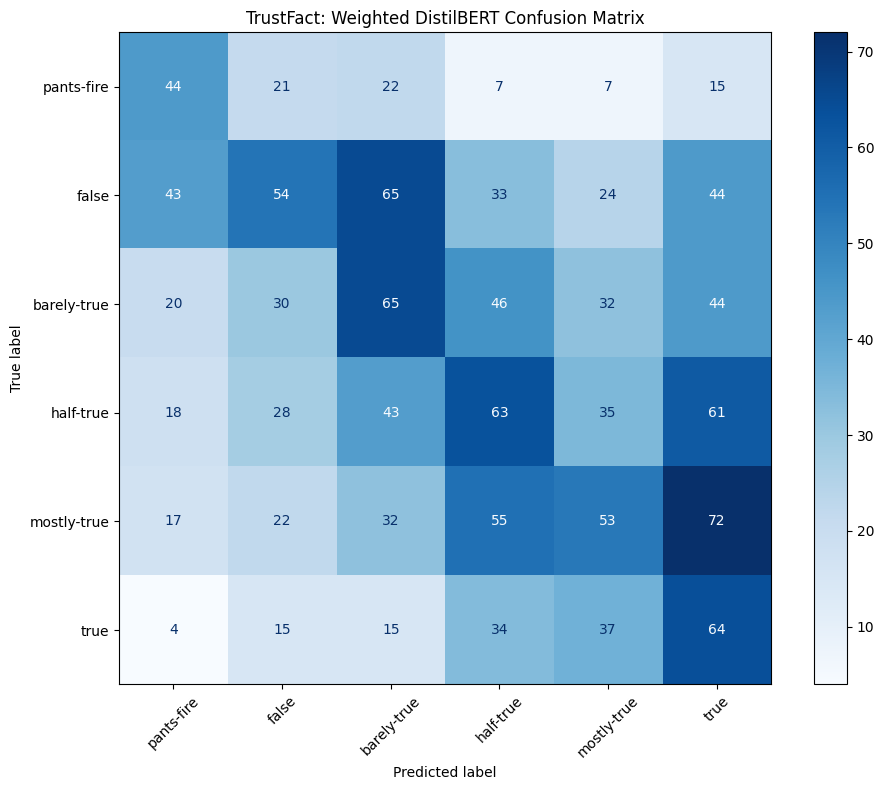

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    actual,
    predictions,
    display_labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("TrustFact: Weighted DistilBERT Confusion Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "weighted_distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
from pathlib import Path
import pandas as pd

# Set Google Drive output directory
week4_dir = Path("/content/drive/MyDrive/TrustFact/results/week4")
week4_dir.mkdir(parents=True, exist_ok=True)

# Create comparison using your verified Week 4 results
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.253115,
        "Macro-F1": 0.232384
    },
    {
        "Model": "Linear SVM",
        "Accuracy": 0.262461,
        "Macro-F1": 0.258223
    },
    {
        "Model": "Optimized Logistic Regression",
        "Accuracy": 0.267134,
        "Macro-F1": 0.261930
    },
    {
        "Model": "Standard DistilBERT",
        "Accuracy": 0.260125,
        "Macro-F1": 0.253645
    },
    {
        "Model": "Weighted DistilBERT",
        "Accuracy": weighted_metrics["eval_accuracy"],
        "Macro-F1": weighted_metrics["eval_macro_f1"]
    }
])

# Sort by highest macro-F1
comparison = comparison.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

display(comparison)

# Save the final comparison
save_path = week4_dir / "final_week4_model_comparison.csv"

comparison.to_csv(save_path, index=False)

print("\nFinal Week 4 comparison saved successfully!")
print("Location:", save_path)
print("File exists:", save_path.exists())

,Model,Accuracy,Macro-F1
0,Weighted DistilBERT,0.267134,0.271723
1,Optimized Logistic Regression,0.267134,0.261930
2,Linear SVM,0.262461,0.258223
3,Standard DistilBERT,0.260125,0.253645
4,Logistic Regression,0.253115,0.232384



Final Week 4 comparison saved successfully!
Location: /content/drive/MyDrive/TrustFact/results/week4/final_week4_model_comparison.csv
File exists: True


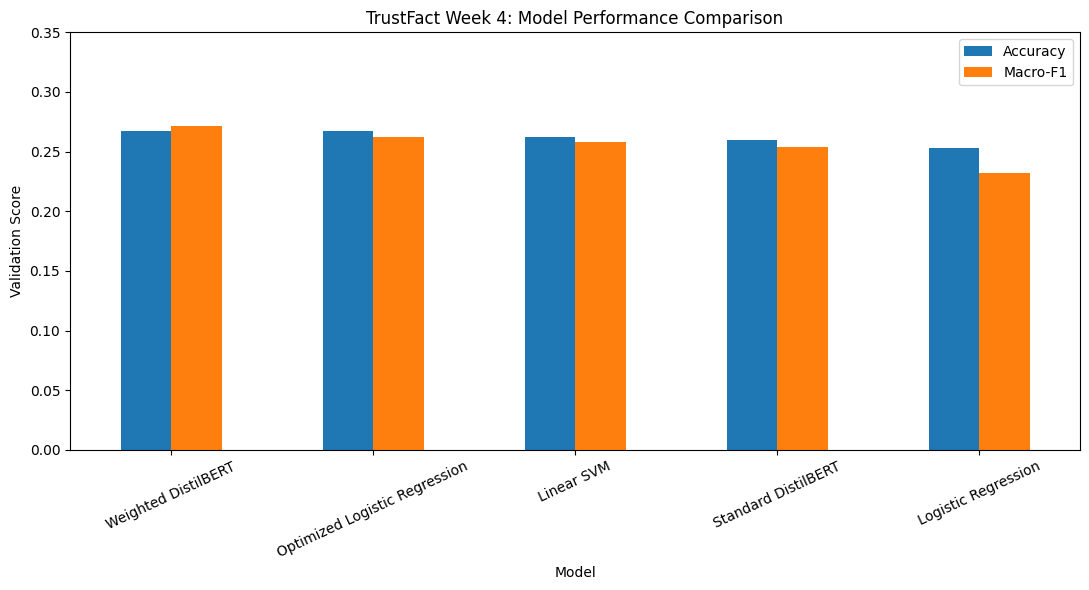

In [18]:
import matplotlib.pyplot as plt

ax = comparison.set_index("Model")[
    ["Accuracy", "Macro-F1"]
].plot(
    kind="bar",
    figsize=(11, 6),
    rot=25
)

plt.title("TrustFact Week 4: Model Performance Comparison")
plt.ylabel("Validation Score")
plt.ylim(0, 0.35)
plt.tight_layout()

plt.savefig(
    week4_dir / "final_week4_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
import pandas as pd

standard = pd.read_csv(
    OUTPUT_DIR / "distilbert_detailed_evaluation.csv",
    index_col=0
)

weighted = pd.read_csv(
    OUTPUT_DIR / "weighted_distilbert_classification_report.csv",
    index_col=0
)

class_comparison = pd.DataFrame({
    "Standard Recall": standard.loc[
        ["pants-fire", "false", "barely-true",
         "half-true", "mostly-true", "true"], "recall"
    ],
    "Weighted Recall": weighted.loc[
        ["pants-fire", "false", "barely-true",
         "half-true", "mostly-true", "true"], "recall"
    ]
})

class_comparison["Recall Change"] = (
    class_comparison["Weighted Recall"]
    - class_comparison["Standard Recall"]
)

display(class_comparison)

class_comparison.to_csv(
    OUTPUT_DIR / "distilbert_per_class_recall_comparison.csv"
)

,Standard Recall,Weighted Recall,Recall Change
pants-fire,0.189655,0.379310,0.189655
false,0.304183,0.205323,-0.098859
barely-true,0.135021,0.274262,0.139241
half-true,0.330645,0.254032,-0.076613
mostly-true,0.278884,0.211155,-0.067729
true,0.284024,0.378698,0.094675


In [20]:
import pandas as pd
from pathlib import Path

summary = pd.DataFrame([
    {
        "Experiment": "Standard DistilBERT",
        "Accuracy": 0.260125,
        "Macro-F1": 0.253645,
        "Loss Function": "Standard cross-entropy"
    },
    {
        "Experiment": "Weighted DistilBERT",
        "Accuracy": 0.267134,
        "Macro-F1": 0.271723,
        "Loss Function": "Class-weighted cross-entropy"
    }
])

summary.to_csv(
    OUTPUT_DIR / "distilbert_experiment_summary.csv",
    index=False
)

display(summary)

print("Experiment summary saved.")

,Experiment,Accuracy,Macro-F1,Loss Function
0,Standard DistilBERT,0.260125,0.253645,Standard cross-entropy
1,Weighted DistilBERT,0.267134,0.271723,Class-weighted cross-entropy


Experiment summary saved.


In [21]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/TrustFact")
DATA_DIR = BASE / "data/raw/liar"
BENCHMARK_DIR = BASE / "results/week4/llm_benchmark"
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

# Select 10 statements from each class
benchmark = (
    valid_df.groupby("label", group_keys=False)
    .sample(n=10, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

benchmark.insert(
    0, "sample_id",
    [f"TF-{i:03d}" for i in range(1, len(benchmark)+1)]
)

# Save ground truth separately
benchmark[["sample_id", "label"]].to_csv(
    BENCHMARK_DIR / "ground_truth.csv",
    index=False
)

# Create a file containing statements without labels
evaluation = benchmark[["sample_id", "statement"]].copy()
evaluation["chatgpt_prediction"] = ""
evaluation["claude_prediction"] = ""

evaluation.to_csv(
    BENCHMARK_DIR / "llm_predictions.csv",
    index=False
)

display(evaluation.head(10))
print("Total statements:", len(evaluation))

,sample_id,statement,chatgpt_prediction,claude_prediction
0,TF-001,Wisconsins technical college graduates have a ...,,
1,TF-002,"Under Obamacare, when you turn Medicaid over t...",,
2,TF-003,Says Barack Obama has pension investments that...,,
3,TF-004,We researched to find out if anybody on Fox Ne...,,
4,TF-005,The Human Rights Campaign is more powerful tha...,,
5,TF-006,Large majorities of the public oppose major ch...,,
6,TF-007,Eight of the nine justices in the Supreme Cour...,,
7,TF-008,Patrick Rose voted to explore a state income tax.,,
8,TF-009,On the Cuba embargo,,
9,TF-010,"The company I created, Point Judith Capital, ""...",,


Total statements: 60


In [22]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/TrustFact")
DATA_DIR = BASE / "data/raw/liar"
BENCHMARK_DIR = BASE / "results/week4/llm_benchmark"

BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

# Select 10 statements from each truthfulness category
benchmark = (
    valid_df.groupby("label", group_keys=False)
    .sample(n=10, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

benchmark.insert(
    0, "sample_id",
    [f"TF-{i:03d}" for i in range(1, len(benchmark) + 1)]
)

# Save actual labels separately
benchmark[["sample_id", "label"]].to_csv(
    BENCHMARK_DIR / "ground_truth.csv",
    index=False
)

# Create file for ChatGPT and Claude predictions
llm_predictions = benchmark[["sample_id", "statement"]].copy()

llm_predictions["chatgpt_prediction"] = ""
llm_predictions["claude_prediction"] = ""

file_path = BENCHMARK_DIR / "llm_predictions.csv"

llm_predictions.to_csv(file_path, index=False)

print("File created:", file_path)
print("File exists:", file_path.exists())
print("Total statements:", len(llm_predictions))

display(llm_predictions.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File created: /content/drive/MyDrive/TrustFact/results/week4/llm_benchmark/llm_predictions.csv
File exists: True
Total statements: 60


,sample_id,statement,chatgpt_prediction,claude_prediction
0,TF-001,Wisconsins technical college graduates have a ...,,
1,TF-002,"Under Obamacare, when you turn Medicaid over t...",,
2,TF-003,Says Barack Obama has pension investments that...,,
3,TF-004,We researched to find out if anybody on Fox Ne...,,
4,TF-005,The Human Rights Campaign is more powerful tha...,,


In [23]:
for file in BENCHMARK_DIR.iterdir():
    print(file.name)

ground_truth.csv
llm_predictions.csv


In [24]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Google Drive mounted:", root.exists())

if root.exists():
    matches = list(root.rglob("llm_predictions.csv"))

    if matches:
        for file in matches:
            print("FOUND:", file)
    else:
        print("FILE NOT FOUND anywhere in MyDrive")

Google Drive mounted: True
FOUND: /content/drive/MyDrive/TrustFact/results/week4/llm_benchmark/llm_predictions.csv


In [25]:
from google.colab import files

files.download(str(file_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import pandas as pd
from pathlib import Path
from io import StringIO

BENCHMARK_DIR = Path(
    "/content/drive/MyDrive/TrustFact/results/week4/llm_benchmark"
)

chatgpt_output = """sample_id,chatgpt_prediction
TF-001,half-true
TF-002,false
TF-003,mostly-true
TF-004,false
TF-005,half-true
TF-006,mostly-true
TF-007,mostly-true
TF-008,mostly-true
TF-009,half-true
TF-010,false
TF-011,pants-fire
TF-012,true
TF-013,mostly-true
TF-014,false
TF-015,mostly-true
TF-016,half-true
TF-017,half-true
TF-018,mostly-true
TF-019,pants-fire
TF-020,mostly-true
TF-021,pants-fire
TF-022,half-true
TF-023,mostly-true
TF-024,mostly-true
TF-025,mostly-true
TF-026,half-true
TF-027,half-true
TF-028,mostly-true
TF-029,half-true
TF-030,half-true
TF-031,half-true
TF-032,barely-true
TF-033,half-true
TF-034,mostly-true
TF-035,false
TF-036,mostly-true
TF-037,mostly-true
TF-038,pants-fire
TF-039,mostly-true
TF-040,mostly-true
TF-041,false
TF-042,half-true
TF-043,mostly-true
TF-044,mostly-true
TF-045,false
TF-046,half-true
TF-047,mostly-true
TF-048,half-true
TF-049,half-true
TF-050,half-true
TF-051,mostly-true
TF-052,half-true
TF-053,mostly-true
TF-054,false
TF-055,half-true
TF-056,false
TF-057,false
TF-058,half-true
TF-059,mostly-true
TF-060,half-true"""

chatgpt_df = pd.read_csv(StringIO(chatgpt_output))

assert len(chatgpt_df) == 60
assert chatgpt_df["sample_id"].is_unique

# Load existing benchmark statements
file_path = BENCHMARK_DIR / "llm_predictions.csv"
benchmark = pd.read_csv(file_path)

assert set(benchmark["sample_id"]) == set(chatgpt_df["sample_id"])

# Update ChatGPT column while preserving statements and Claude results
benchmark = benchmark.drop(
    columns=["chatgpt_prediction"],
    errors="ignore"
)

benchmark = benchmark.merge(
    chatgpt_df,
    on="sample_id",
    how="left",
    validate="one_to_one"
)

benchmark.to_csv(file_path, index=False)

print("ChatGPT predictions saved:", len(chatgpt_df))
print("File:", file_path)
display(benchmark.head(10))

ChatGPT predictions saved: 60
File: /content/drive/MyDrive/TrustFact/results/week4/llm_benchmark/llm_predictions.csv


,sample_id,statement,claude_prediction,chatgpt_prediction
0,TF-001,Wisconsins technical college graduates have a ...,NaN,half-true
1,TF-002,"Under Obamacare, when you turn Medicaid over t...",NaN,false
2,TF-003,Says Barack Obama has pension investments that...,NaN,mostly-true
3,TF-004,We researched to find out if anybody on Fox Ne...,NaN,false
4,TF-005,The Human Rights Campaign is more powerful tha...,NaN,half-true
5,TF-006,Large majorities of the public oppose major ch...,NaN,mostly-true
6,TF-007,Eight of the nine justices in the Supreme Cour...,NaN,mostly-true
7,TF-008,Patrick Rose voted to explore a state income tax.,NaN,mostly-true
8,TF-009,On the Cuba embargo,NaN,half-true
9,TF-010,"The company I created, Point Judith Capital, ""...",NaN,false


In [27]:
print(chatgpt_df["chatgpt_prediction"].value_counts())

chatgpt_prediction
mostly-true    23
half-true      21
false          10
pants-fire      4
true            1
barely-true     1
Name: count, dtype: int64


In [28]:
import pandas as pd
from pathlib import Path
from io import StringIO

BENCHMARK_DIR = Path(
    "/content/drive/MyDrive/TrustFact/results/week4/llm_benchmark"
)

claude_output = """sample_id,claude_prediction
TF-001,half-true
TF-002,mostly-true
TF-003,false
TF-004,false
TF-005,false
TF-006,mostly-true
TF-007,mostly-true
TF-008,true
TF-009,half-true
TF-010,half-true
TF-011,pants-fire
TF-012,true
TF-013,mostly-true
TF-014,half-true
TF-015,mostly-true
TF-016,false
TF-017,barely-true
TF-018,true
TF-019,pants-fire
TF-020,half-true
TF-021,pants-fire
TF-022,barely-true
TF-023,mostly-true
TF-024,half-true
TF-025,mostly-true
TF-026,half-true
TF-027,barely-true
TF-028,barely-true
TF-029,false
TF-030,half-true
TF-031,mostly-true
TF-032,half-true
TF-033,half-true
TF-034,mostly-true
TF-035,false
TF-036,half-true
TF-037,true
TF-038,pants-fire
TF-039,half-true
TF-040,mostly-true
TF-041,false
TF-042,false
TF-043,half-true
TF-044,half-true
TF-045,false
TF-046,barely-true
TF-047,half-true
TF-048,half-true
TF-049,pants-fire
TF-050,mostly-true
TF-051,barely-true
TF-052,mostly-true
TF-053,half-true
TF-054,false
TF-055,half-true
TF-056,mostly-true
TF-057,false
TF-058,false
TF-059,true
TF-060,half-true"""

claude_df = pd.read_csv(StringIO(claude_output))

assert len(claude_df) == 60
assert claude_df["sample_id"].is_unique

file_path = BENCHMARK_DIR / "llm_predictions.csv"
assert file_path.exists(), f"Missing benchmark file: {file_path}"

benchmark = pd.read_csv(file_path)

assert set(benchmark["sample_id"]) == set(claude_df["sample_id"])

# Preserve the ChatGPT predictions
benchmark = benchmark.drop(
    columns=["claude_prediction"],
    errors="ignore"
)

benchmark = benchmark.merge(
    claude_df,
    on="sample_id",
    how="left",
    validate="one_to_one"
)

benchmark.to_csv(file_path, index=False)

print("Claude predictions saved:", len(claude_df))
print("ChatGPT predictions:",
      benchmark["chatgpt_prediction"].notna().sum())
print("File:", file_path)

display(benchmark.head(10))

Claude predictions saved: 60
ChatGPT predictions: 60
File: /content/drive/MyDrive/TrustFact/results/week4/llm_benchmark/llm_predictions.csv


,sample_id,statement,chatgpt_prediction,claude_prediction
0,TF-001,Wisconsins technical college graduates have a ...,half-true,half-true
1,TF-002,"Under Obamacare, when you turn Medicaid over t...",false,mostly-true
2,TF-003,Says Barack Obama has pension investments that...,mostly-true,false
3,TF-004,We researched to find out if anybody on Fox Ne...,false,false
4,TF-005,The Human Rights Campaign is more powerful tha...,half-true,false
5,TF-006,Large majorities of the public oppose major ch...,mostly-true,mostly-true
6,TF-007,Eight of the nine justices in the Supreme Cour...,mostly-true,mostly-true
7,TF-008,Patrick Rose voted to explore a state income tax.,mostly-true,true
8,TF-009,On the Cuba embargo,half-true,half-true
9,TF-010,"The company I created, Point Judith Capital, ""...",false,half-true


In [29]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

truth = pd.read_csv(BENCHMARK_DIR / "ground_truth.csv")
preds = pd.read_csv(BENCHMARK_DIR / "llm_predictions.csv")

df = truth.merge(
    preds,
    on="sample_id",
    validate="one_to_one"
)

labels = [
    "pants-fire", "false", "barely-true",
    "half-true", "mostly-true", "true"
]

assert len(df) == 60
assert df["label"].value_counts().eq(10).all()

for col in ["chatgpt_prediction", "claude_prediction"]:
    assert df[col].isin(labels).all(), f"Missing or invalid: {col}"

results = []

for name, column in [
    ("ChatGPT", "chatgpt_prediction"),
    ("Claude", "claude_prediction")
]:
    accuracy = accuracy_score(df["label"], df[column])
    macro_f1 = f1_score(
        df["label"],
        df[column],
        labels=labels,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

    print(f"\n{name.upper()} CLASSIFICATION REPORT")
    print(classification_report(
        df["label"],
        df[column],
        labels=labels,
        zero_division=0
    ))

comparison = pd.DataFrame(results).sort_values(
    "Macro-F1",
    ascending=False
)

display(comparison)

comparison.to_csv(
    BENCHMARK_DIR / "chatgpt_claude_comparison.csv",
    index=False
)

print("LLM comparison saved successfully!")


CHATGPT CLASSIFICATION REPORT
              precision    recall  f1-score   support

  pants-fire       1.00      0.40      0.57        10
       false       0.20      0.20      0.20        10
 barely-true       0.00      0.00      0.00        10
   half-true       0.19      0.40      0.26        10
 mostly-true       0.30      0.70      0.42        10
        true       1.00      0.10      0.18        10

    accuracy                           0.30        60
   macro avg       0.45      0.30      0.27        60
weighted avg       0.45      0.30      0.27        60


CLAUDE CLASSIFICATION REPORT
              precision    recall  f1-score   support

  pants-fire       1.00      0.50      0.67        10
       false       0.33      0.40      0.36        10
 barely-true       0.17      0.10      0.12        10
   half-true       0.16      0.30      0.21        10
 mostly-true       0.23      0.30      0.26        10
        true       0.60      0.30      0.40        10

    accuracy    

,Model,Accuracy,Macro-F1
1,Claude,0.316667,0.337178
0,ChatGPT,0.300000,0.272592


LLM comparison saved successfully!


In [30]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_DIR = Path(
    "/content/drive/MyDrive/TrustFact/results/week4/"
    "distilbert/weighted_best_model"
)

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))
model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model.to(device)
model.eval()

trustfact_predictions = []

for start in range(0, len(df), 16):
    batch = df["statement"].iloc[start:start + 16].tolist()

    inputs = tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits

    predicted_ids = logits.argmax(dim=1).cpu().tolist()

    trustfact_predictions.extend([
        model.config.id2label[i] for i in predicted_ids
    ])

df["trustfact_prediction"] = trustfact_predictions

assert df["trustfact_prediction"].isin(labels).all()

trustfact_row = pd.DataFrame([{
    "Model": "TrustFact Weighted DistilBERT",
    "Accuracy": accuracy_score(
        df["label"], df["trustfact_prediction"]
    ),
    "Macro-F1": f1_score(
        df["label"],
        df["trustfact_prediction"],
        labels=labels,
        average="macro",
        zero_division=0
    )
}])

final_comparison = pd.concat(
    [comparison, trustfact_row],
    ignore_index=True
).sort_values("Macro-F1", ascending=False)

display(final_comparison)

final_comparison.to_csv(
    BENCHMARK_DIR / "trustfact_chatgpt_claude_comparison.csv",
    index=False
)

df.to_csv(
    BENCHMARK_DIR / "all_model_predictions.csv",
    index=False
)

print("Three-model benchmark completed!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,Model,Accuracy,Macro-F1
2,TrustFact Weighted DistilBERT,0.350000,0.360688
0,Claude,0.316667,0.337178
1,ChatGPT,0.300000,0.272592


Three-model benchmark completed!


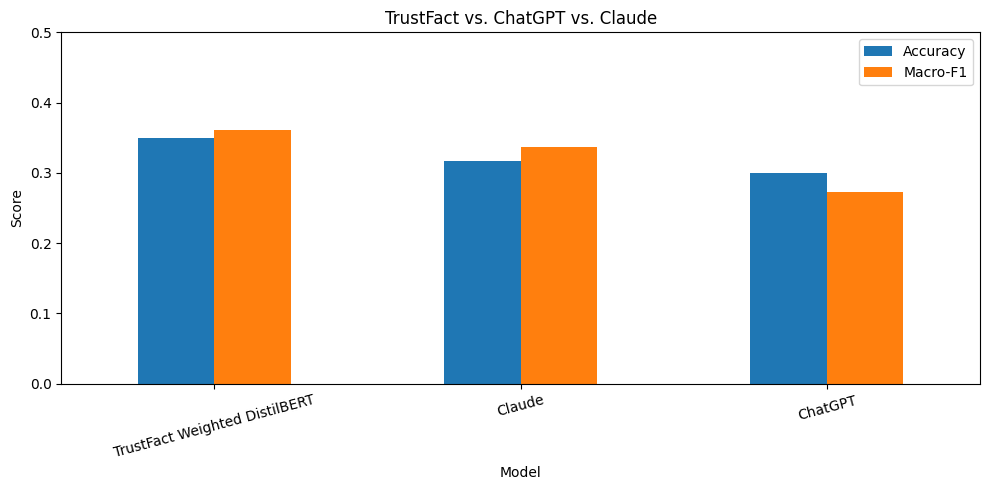

In [31]:
import matplotlib.pyplot as plt

ax = final_comparison.set_index("Model")[
    ["Accuracy", "Macro-F1"]
].plot(kind="bar", figsize=(10, 5), rot=15)

plt.title("TrustFact vs. ChatGPT vs. Claude")
plt.ylabel("Score")
plt.ylim(0, 0.5)
plt.tight_layout()

plt.savefig(
    BENCHMARK_DIR / "three_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

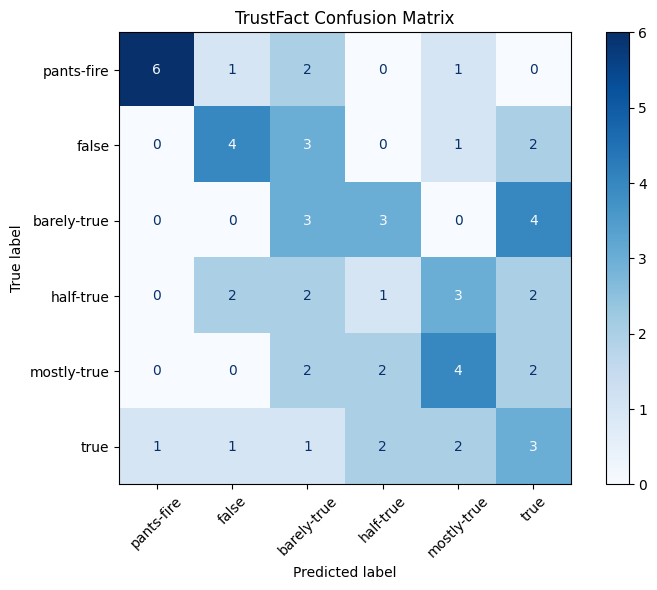

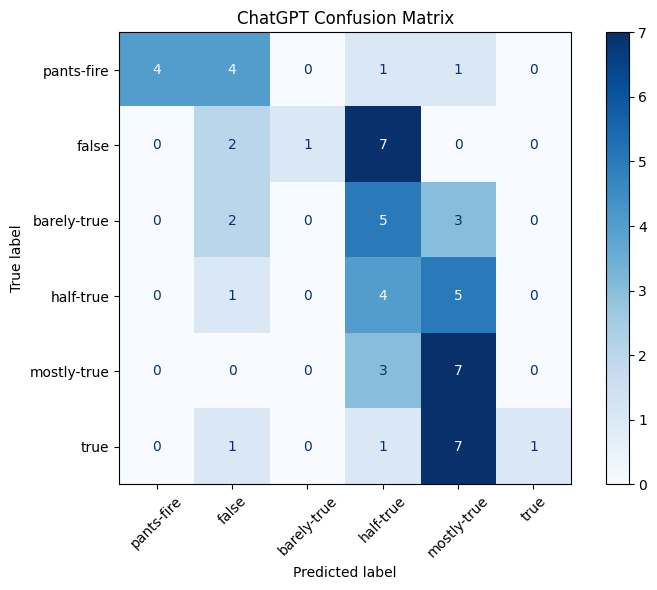

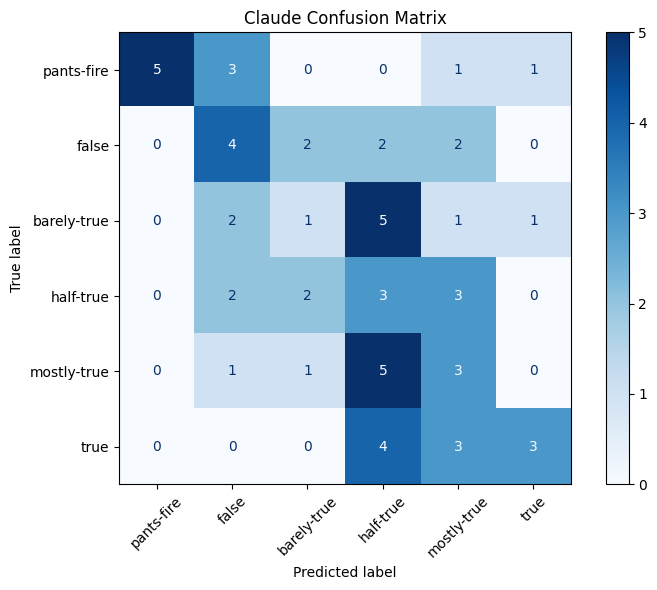

All evaluation reports and figures saved.


In [32]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

model_columns = {
    "TrustFact": "trustfact_prediction",
    "ChatGPT": "chatgpt_prediction",
    "Claude": "claude_prediction"
}

for name, column in model_columns.items():
    report = classification_report(
        df["label"],
        df[column],
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        BENCHMARK_DIR / f"{name.lower()}_report.csv"
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        df["label"],
        df[column],
        labels=labels,
        display_labels=labels,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        BENCHMARK_DIR / f"{name.lower()}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("All evaluation reports and figures saved.")